# Los diez muestreos del HP500 y el motor calibrado corrido en cada uno

**Pregunta:** ¿Qué midió un cono secundario HP500 industrial en diez muestreos de planta, y qué tan cerca llega el motor calibrado al tonelaje de cada uno con la misma abertura y el mismo tamaño de alimentación?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los notebooks 01 y 02 del tema 01-getting-started
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook usted puede:

- leer la tabla de muestreos del cono secundario HP500 y decir qué cantidades se midieron y cuáles no;
- explicar qué toma del muestreo la vía calibrada del motor y qué fija como constantes de la máquina;
- correr el motor en cada uno de los diez muestreos y poner el tonelaje modelado junto al medido;
- leer el error de cada muestreo y el error medio, y decir qué esconde un solo número.

## Preparación

Numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son el lector de muestreos, el punto de operación de la vía calibrada y el motor, con el ayudante de códigos de aviso que convierte los textos de aviso del motor en códigos estables.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.hp500 import HP500_NOMINAL, HP500_FEED_M, x63_from_f80
from pipeline.core.manifest import flag_codes
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos de un chancador de cono secundario Metso HP500 en la operación de mineral de hierro itabirita de Minas Rio. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivo leído: `data/examples/hp500-surveys.csv`, cinco columnas: el número de muestreo, el f80 de alimentación en mm, la abertura de lado cerrado en mm, el flujo de alimentación en t/h y la potencia en kW. El artículo informa los tamaños de producto solo en figuras, así que la tabla no tiene P80 medido.

La celda lee la tabla con el lector del pipeline, que valida cada fila, e imprime los rangos de las cuatro columnas medidas.

In [2]:
# Lea la tabla de muestreos con el lector validador del pipeline e imprima el rango de cada columna medida
report = read_surveys()
surveys = report.accepted
print("filas aceptadas:", len(surveys), "| rechazadas:", len(report.rejected))
for name in ("css_mm", "f80_mm", "feed_tph", "power_kw"):
    values = [getattr(s, name) for s in surveys]
    print(f"{name:9s} min {min(values):7.1f}  max {max(values):7.1f}")

filas aceptadas: 10 | rechazadas: 0
css_mm    min    38.0  max    55.0
f80_mm    min    47.0  max   140.0
feed_tph  min   813.0  max  1639.0
power_kw  min   187.0  max   355.0


## Método

**Paso 1, qué entrega un muestreo al motor.** La vía calibrada se construye con el ajuste de Andersen-Whiten de Rocha et al. (2024; https://doi.org/10.3390/min14090919, Tabla 5), lineal en la abertura y en el f80 de alimentación. Un muestreo aporta exactamente esos dos números. Todo lo demás es una constante de la máquina o un supuesto: la carrera y la velocidad son los valores nominales del HP500, y la forma de la alimentación se reconstruye desde el f80 con una uniformidad de Rosin-Rammler fija en 0,9, porque el artículo informa solo el f80. Invertir la ley con 80 por ciento pasante da $x_{63} = f_{80} / (\ln 5)^{1/m}$. La celda imprime las constantes y el punto de operación del muestreo 1.

In [3]:
# Las constantes de máquina de la vía y el punto de operación construido desde el muestreo 1
print("carrera y velocidad nominales:", HP500_NOMINAL, "| uniformidad de alimentación m =", HP500_FEED_M)
first = surveys[0]
print("x63 desde f80 = 88 mm:", round(x63_from_f80(first.f80_mm), 3), "mm")
print(operating_from_survey(first.css_mm, first.f80_mm))

carrera y velocidad nominales: Hp500Nominal(throw_mm=34, speed_rpm=360) | uniformidad de alimentación m = 0.9
x63 desde f80 = 88 mm: 51.861 mm
Operating(machine='cone-sec', css_mm=54.0, throw_mm=34, speed_rpm=360, feed_x63_mm=51.8614483895739, feed_m=0.9, ore_axb=677.3, ore_wi=9.0, calibrated=True)


**Paso 2, la corrida.** La celda evalúa el motor en cada uno de los diez muestreos, con la vía calibrada activa, y lista para cada uno el tonelaje medido y el modelado, el error como porcentaje de la medición, el P80 del modelo y los códigos de aviso que levanta el motor. El error es $(Q_{modelo} - Q_{medido}) / Q_{medido}$, de modo que un signo negativo significa que el modelo queda bajo la planta.

In [4]:
# Corra el motor calibrado en los diez muestreos y liste el tonelaje medido y el modelado y los avisos
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
errors = np.array([(r.throughput_tph - s.feed_tph) / s.feed_tph * 100 for r, s in zip(runs, surveys)])
print("muestreo CSS   f80   medido    modelo   error    P80   avisos")
for s, r, e in zip(surveys, runs, errors):
    print(f"{s.survey:6d} {s.css_mm:5.0f} {s.f80_mm:5.0f} {s.feed_tph:9.0f} {r.throughput_tph:8.1f} {e:+7.1f} % {r.p80:6.2f}   {flag_codes(r)}")
print("error absoluto medio:", round(float(np.abs(errors).mean()), 2), "%")

muestreo CSS   f80   medido    modelo   error    P80   avisos
     1    54    88      1639   1208.9   -26.2 %  32.56   []
     2    54    84      1267   1208.9    -4.6 %  31.36   []
     3    48    47      1240   1106.7   -10.7 %  21.23   ['pass_through', 'f80_lt_css']
     4    48    88      1034   1106.7    +7.0 %  30.80   []
     5    48    62      1124   1106.7    -1.5 %  24.54   []
     6    40    79       813    970.5   +19.4 %  26.54   []
     7    38   140      1050    936.4   -10.8 %  36.60   []
     8    44   123      1138   1038.6    -8.7 %  35.69   []
     9    40    81       820    970.5   +18.4 %  26.97   []
    10    55    81      1334   1225.9    -8.1 %  30.72   []
error absoluto medio: 11.55 %


La figura pone los diez pares en un gráfico de paridad: un punto sobre la diagonal es una predicción perfecta, y un punto bajo ella es un modelo que queda corto. Las etiquetas son los números de muestreo.

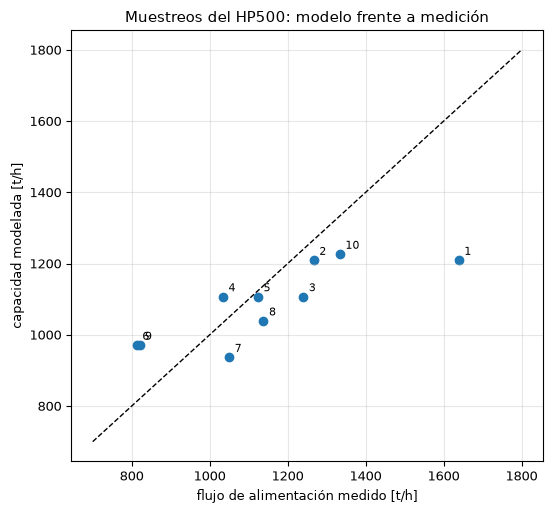

In [5]:
# Gráfico de paridad del tonelaje modelado contra el medido, rotulado por muestreo
measured = np.array([s.feed_tph for s in surveys])
modelled = np.array([r.throughput_tph for r in runs])
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([700, 1800], [700, 1800], "k--", lw=1)
ax.scatter(measured, modelled)
for s, x, y in zip(surveys, measured, modelled):
    ax.annotate(str(s.survey), (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("flujo de alimentación medido [t/h]")
ax.set_ylabel("capacidad modelada [t/h]")
ax.set_title("Muestreos del HP500: modelo frente a medición")
fig.tight_layout()
plt.show()

Los puntos se dispersan en torno a la diagonal con una leve tendencia a quedar bajo ella: siete quedan bajo ella y tres sobre ella, y el más lejano, el muestreo 1, está en 1639 t/h medidos frente a 1209 modelados. La estructura vertical es la pista de por qué: los valores modelados vienen en pocos niveles, 1209, 1107, 970 y otros, mientras los medidos se dispersan libremente, porque la capacidad del motor depende de la abertura y no del f80 de alimentación. La figura muestra qué tan lejos queda cada punto, no por qué; la figura siguiente grafica los mismos datos contra la abertura.

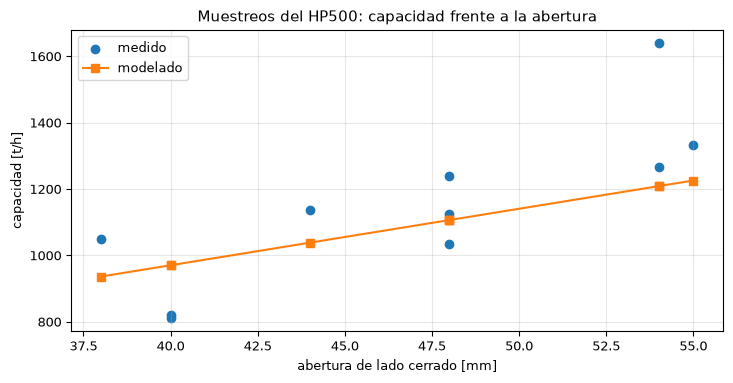

In [6]:
# Tonelaje medido y modelado contra la abertura de lado cerrado
settings = np.array([s.css_mm for s in surveys])
order = np.argsort(settings)
fig, ax = plt.subplots()
ax.scatter(settings, measured, label="medido")
ax.plot(settings[order], modelled[order], "s-", color="tab:orange", label="modelado")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("capacidad [t/h]")
ax.set_title("Muestreos del HP500: capacidad frente a la abertura")
ax.legend()
fig.tight_layout()
plt.show()

La línea del modelo es función solo de la abertura: sube de 936 t/h con 38 mm a 1226 t/h con 55 mm, un camino suave por la nube. Los puntos medidos siguen la misma tendencia, y en torno a ella se dispersan hasta 400 t/h con la misma abertura (muestreos 1 y 2, con 54 mm, medidos 1639 y 1267 t/h). Esa dispersión es lo que el modelo deja sin explicar, sea la alimentación, la mezcla de mineral o el estado de los revestimientos, y una abertura no puede dar dos capacidades. La figura sostiene una afirmación de tendencia, no una de predicción para un muestreo individual.

**Paso 3, qué lee el motor del f80.** La dispersión del tonelaje medido con una misma abertura plantea la pregunta de qué hace el motor con la otra variable del muestreo. La celda mantiene la abertura en 48 mm, la de los muestreos 3, 4 y 5, y corre el motor calibrado con cinco tamaños de alimentación de 47 a 140 mm, el rango de los muestreos.

In [7]:
# Corra el motor calibrado con una abertura fija de 48 mm en el rango de f80 de los muestreos
for f80_mm in (47, 60, 90, 120, 140):
    r = evaluate(operating_from_survey(48, f80_mm))
    print(f"f80 {f80_mm:4d} mm: throughput {r.throughput_tph:7.1f} t/h  P80 {r.p80:5.2f} mm  reduction ratio {r.reduction_ratio:4.2f}")

f80   47 mm: throughput  1106.7 t/h  P80 21.23 mm  reduction ratio 2.22
f80   60 mm: throughput  1106.7 t/h  P80 24.21 mm  reduction ratio 2.47
f80   90 mm: throughput  1106.7 t/h  P80 31.39 mm  reduction ratio 2.75
f80  120 mm: throughput  1106.7 t/h  P80 36.04 mm  reduction ratio 3.00
f80  140 mm: throughput  1106.7 t/h  P80 38.91 mm  reduction ratio 3.06


El tonelaje es exactamente el mismo, 1106,7 t/h, con todos los tamaños de alimentación, mientras el P80 del producto pasa de 21,23 a 38,91 mm. En este motor el tamaño de la alimentación fija el producto y la abertura fija el tonelaje. Esa es la ley de capacidad del tema 04, que no tiene un término de alimentación, y es la razón de que los puntos del modelo en la segunda figura queden sobre una línea. También es un supuesto que conviene conocer: en una planta real una alimentación más gruesa sí cambia la tasa a la que se puede alimentar el chancador, y los muestreos 3, 4 y 5, que comparten abertura y difieren en f80, midieron 1240, 1034 y 1124 t/h.

**Paso 4, el soporte de la calibración.** El ajuste es válido para aberturas de 38 a 55 mm y f80 de alimentación de 47 a 140 mm, el rango de los diez muestreos, y la compuerta de envolvente del motor marca un punto calibrado fuera de él como extrapolación, con los códigos `css_outside_calibrated` y `f80_outside_calibrated`. La celda evalúa cuatro puntos, uno dentro del soporte, dos con la abertura fuera y uno con una alimentación de 180 mm, e imprime el veredicto de la compuerta y el F80 que ve la compuerta.

In [8]:
# Evalúe cuatro puntos calibrados e imprima el veredicto de la compuerta de envolvente y el F80 que ve
for css_mm, f80_mm in ((46, 90), (30, 90), (60, 100), (46, 180)):
    r = evaluate(operating_from_survey(css_mm, f80_mm))
    print(f"CSS {css_mm} mm, f80 {f80_mm} mm: engine F80 {r.f80:6.1f} mm, outside the support: {r.out_of_envelope}, codes {list(r.envelope_codes)}")

CSS 46 mm, f80 90 mm: engine F80   86.4 mm, outside the support: False, codes []
CSS 30 mm, f80 90 mm: engine F80   86.4 mm, outside the support: True, codes ['css_outside_calibrated']
CSS 60 mm, f80 100 mm: engine F80   94.2 mm, outside the support: True, codes ['css_outside_calibrated']
CSS 46 mm, f80 180 mm: engine F80  135.8 mm, outside the support: False, codes []


Los dos puntos con una abertura fuera de 38 a 55 mm son marcados, como se pretende. El punto con una alimentación de 180 mm no: la compuerta prueba el F80 que calcula el motor, y la malla del motor termina en 256 mm, de modo que el F80 de esa alimentación ya está recortado a un valor dentro del soporte, como explica el notebook 01 del tema 02. Quien pide una alimentación sobre el rango muestreado no recibe entonces aviso del chequeo de f80, un límite de la compuerta que el chequeo de abertura no comparte. La marca es evidencia de extrapolación cuando se levanta, y su ausencia no es evidencia de interpolación.

## Resultados

**Respuesta:** el error absoluto medio de tonelaje del motor calibrado en los diez muestreos es 11,55 por ciento, con errores individuales desde -26,2 por ciento (muestreo 1, 1209 frente a 1639 t/h) hasta +19,4 por ciento (muestreo 6, 970 frente a 813 t/h), siete muestreos sub-predichos y tres sobre-predichos, y un error medio de -2,6 por ciento. El muestreo 3 es el que el motor marca: su f80 de 47 mm está bajo su abertura de 48 mm, así que el motor levanta `pass_through` y `f80_lt_css` y marca el punto como inválido, aunque el error de su tonelaje, -10,7 por ciento (1107 frente a 1240 t/h), está cerca del error absoluto medio.

La primera figura muestra un leve sesgo hacia abajo y la segunda explica la dispersión: el tonelaje del motor es función de la abertura, de modo que sigue la tendencia de la planta y no puede seguir la variación entre muestreos con una misma abertura. Un validador concluiría que el motor tiene el orden de magnitud correcto y la tendencia correcta en la única cantidad que la planta midió como flujo, y que un error medio de 11,55 por ciento en diez puntos es un número descriptivo, no una garantía de desempeño: se calculó dentro de la muestra, con las constantes del artículo que se ajustaron a los mismos muestreos. El notebook 02 lee los errores uno a uno, y el tema 06 pregunta qué sobrevive a una validación con datos retenidos.

## Resumen

Un muestreo entrega al motor calibrado una abertura y un f80; el resto de la máquina y la forma de la alimentación están fijos. En los diez muestreos del HP500 el tonelaje del motor sigue la tendencia de la planta con un error absoluto medio cercano a 12 por ciento y un leve sesgo hacia abajo, y no puede reproducir la variación de la planta con una abertura dada. El muestreo 3 marcado muestra la negativa propia del motor en acción. El notebook 02 lleva la comparación más lejos, al tamaño del producto y a la potencia, y a las preguntas que cada uno plantea.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193